# Kathbath Dataset — Metadata and Audio EDA
This notebook covers metadata quality, dataset distributions, and technical audio validation for Hindi, Tamil, and Telugu. The full audio audit is saved as kathbath_audio_quality_full.csv in the current working directory. Librosa-based acoustic feature analysis is run on a reproducible sample to keep runtime manageable.

## 1. Load the dataset

In [17]:
from datasets import load_dataset, Audio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import io
import soundfile as sf
import json
import hashlib
import time
import librosa
import librosa.display

SEED = 42
LANGUAGES = {
    "Hindi": "hindi",
    "Tamil": "tamil",
    "Telugu": "telugu"
}

datasets_by_language = {
    display_name: load_dataset("ai4bharat/Kathbath", config_name)
    for display_name, config_name in LANGUAGES.items()
}

for language, dataset in datasets_by_language.items():
    print(f"\n{language}")
    for split_name, split_data in dataset.items():
        print(f"  {split_name}: {len(split_data):,} records")
    print("  Columns:", dataset[next(iter(dataset))].column_names)

Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/32 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/33 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/42 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/22 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/33 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/34 [00:00<?, ?it/s]


Hindi
  valid: 3,151 records
  train: 91,752 records
  Columns: ['fname', 'text', 'audio_filepath', 'lang', 'duration', 'gender', 'speaker_id']

Tamil
  valid: 2,770 records
  train: 95,762 records
  Columns: ['fname', 'text', 'audio_filepath', 'lang', 'duration', 'gender', 'speaker_id']

Telugu
  valid: 2,379 records
  train: 70,673 records
  Columns: ['fname', 'text', 'audio_filepath', 'lang', 'duration', 'gender', 'speaker_id']


## 2. Metadata table


In [18]:
metadata_parts = []

required_columns = [
    "fname", "text", "lang", "duration", "gender", "speaker_id"
]

for language, dataset in datasets_by_language.items():
    for split_name, split_data in dataset.items():
        part = split_data.select_columns(required_columns).to_pandas()
        part.insert(0, "split", split_name)
        part.insert(0, "language", language)
        metadata_parts.append(part)

metadata_df = pd.concat(metadata_parts, ignore_index=True)

print(f"Total records: {len(metadata_df):,}")
display(metadata_df.head())

Total records: 266,487


,language,split,fname,text,lang,duration,gender,speaker_id
0,Hindi,valid,844424930524026-252-f.m4a,हमने ओबीसी तबके के बच्चों के लिए उच्च शिक्षा म...,hi,4.017062,Female,252
1,Hindi,valid,844424930612535-939-f.m4a,उसको छोड़कर लोग इस प्रकार के मुद्दो पर चर्चा क...,hi,4.806563,Female,939
2,Hindi,valid,844424930869370-252-f.m4a,उन्होंने कहा कि अतिथि अध्यापको को हटाना न्यायस...,hi,3.738437,Female,252
3,Hindi,valid,844424931201045-939-f.m4a,चीन में मोबाइल फोन की लत एक युवती को बड़ी मुश्...,hi,4.853000,Female,939
4,Hindi,valid,844424931205944-164-f.m4a,मगर साथ में मनपसंद साथी हो तो मेहनत भी रास आती है,hi,3.784875,Female,164


## 3. Dataset distribution

,language,split,records
0,Hindi,train,91752
1,Hindi,valid,3151
2,Tamil,train,95762
3,Tamil,valid,2770
4,Telugu,train,70673
5,Telugu,valid,2379


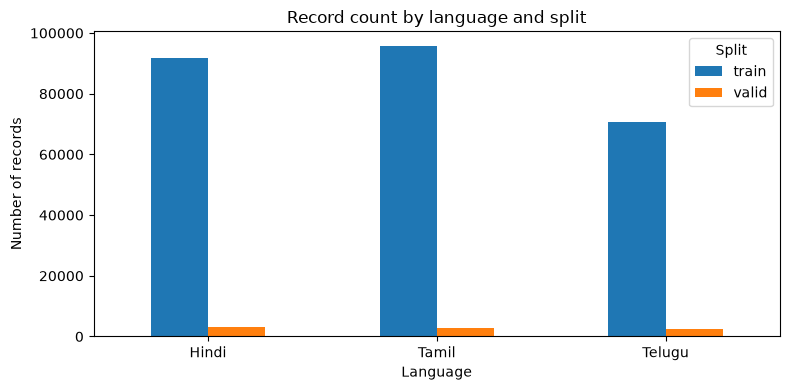

In [19]:
distribution_df = (
    metadata_df.groupby(["language", "split"])
    .size()
    .rename("records")
    .reset_index()
)
display(distribution_df)

pivot = distribution_df.pivot(
    index="language", columns="split", values="records"
).fillna(0)

ax = pivot.plot(kind="bar", figsize=(8, 4))
ax.set_title("Record count by language and split")
ax.set_xlabel("Language")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Split")
plt.tight_layout()
plt.show()

## 3.1 Gender-wise Distribution

In [20]:
# Gender-wise distribution by language and split
gender_counts = (
    metadata_df
    .groupby(["language", "split", "gender"], dropna=False)
    .size()
    .reset_index(name="records")
)

gender_counts["percentage"] = (
    gender_counts["records"]
    / gender_counts.groupby(["language", "split"])["records"].transform("sum")
    * 100
)

display(gender_counts.round(2))

,language,split,gender,records,percentage
0,Hindi,train,Female,68390,74.54
1,Hindi,train,Male,23362,25.46
2,Hindi,valid,Female,1824,57.89
3,Hindi,valid,Male,1327,42.11
4,Tamil,train,Female,55866,58.34
5,Tamil,train,Male,39896,41.66
6,Tamil,valid,Female,1460,52.71
7,Tamil,valid,Male,1310,47.29
8,Telugu,train,Female,46737,66.13
9,Telugu,train,Male,23936,33.87


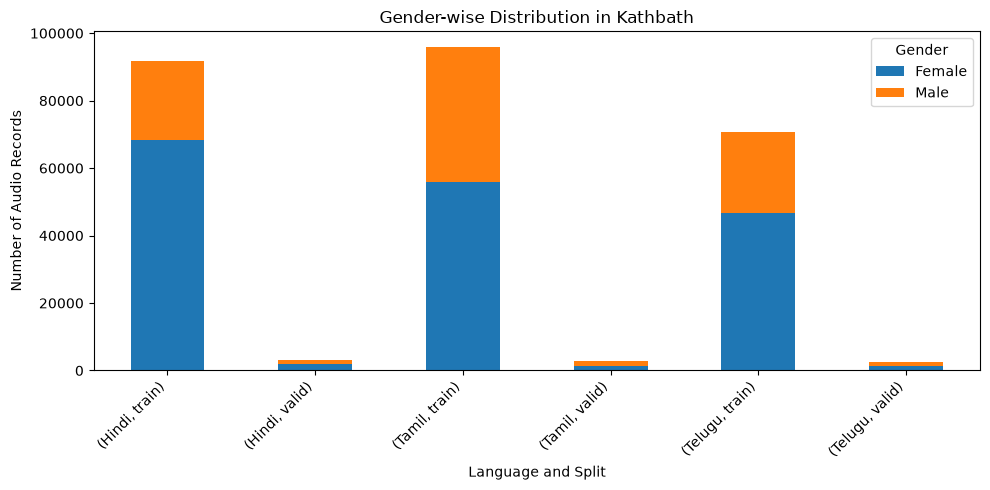

In [21]:
gender_pivot = metadata_df.pivot_table(
    index=["language", "split"],
    columns="gender",
    values="fname",
    aggfunc="count",
    fill_value=0
)

gender_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Gender-wise Distribution in Kathbath")
plt.xlabel("Language and Split")
plt.ylabel("Number of Audio Records")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

## 4. Metadata quality audit

In [22]:
metadata_quality_rows = []

for (language, split_name), df in metadata_df.groupby(["language", "split"]):
    metadata_quality_rows.append({
        "Language": language,
        "Split": split_name,
        "Records": len(df),
        "Missing cells (selected columns)": int(df[required_columns].isna().sum().sum()),
        "Missing filenames": int(df["fname"].isna().sum()),
        "Blank transcripts": int(df["text"].fillna("").astype(str).str.strip().eq("").sum()),
        "Duplicate filenames": int(df["fname"].duplicated().sum()),
        "Duplicate transcripts": int(df["text"].duplicated().sum()),
        "Unique speakers": int(df["speaker_id"].nunique()),
        "Missing durations": int(df["duration"].isna().sum())
    })

metadata_quality_df = pd.DataFrame(metadata_quality_rows)
display(metadata_quality_df)

,Language,Split,Records,Missing cells (selected columns),Missing filenames,Blank transcripts,Duplicate filenames,Duplicate transcripts,Unique speakers,Missing durations
0,Hindi,train,91752,0,0,0,0,18,101,0
1,Hindi,valid,3151,0,0,0,0,0,20,0
2,Tamil,train,95762,0,0,0,0,62,138,0
3,Tamil,valid,2770,0,0,0,0,0,20,0
4,Telugu,train,70673,0,0,0,0,1,84,0
5,Telugu,valid,2379,0,0,0,0,0,20,0


In [23]:
# Check repeated transcripts across different speakers

train_df = metadata_df[metadata_df["split"] == "train"].copy()

# Group identical transcripts within each language
repeated_transcripts = (
    train_df.groupby(["language", "text"])
    .agg(
        occurrences=("speaker_id", "size"),
        unique_speakers=("speaker_id", "nunique"),
        speaker_ids=("speaker_id", lambda x: list(x.unique()))
    )
    .reset_index()
)

# Keep transcripts appearing more than once
repeated_transcripts = repeated_transcripts[
    repeated_transcripts["occurrences"] > 1
].copy()

# Identify transcripts used by multiple speakers
different_speaker_transcripts = repeated_transcripts[
    repeated_transcripts["unique_speakers"] > 1
].copy()

print("Repeated transcripts:", len(repeated_transcripts))
print("Repeated transcripts spoken by different speakers:",
      len(different_speaker_transcripts))

# Summary by language
summary = (
    repeated_transcripts.groupby("language")
    .agg(
        Repeated_transcripts=("text", "count"),
        Used_by_multiple_speakers=(
            "unique_speakers",
            lambda x: (x > 1).sum()
        )
    )
    .reset_index()
)

display(summary)

# View examples
display(
    different_speaker_transcripts[
        ["language", "text", "occurrences", "unique_speakers", "speaker_ids"]
    ].head(10)
)

Repeated transcripts: 81
Repeated transcripts spoken by different speakers: 79


,language,Repeated_transcripts,Used_by_multiple_speakers
0,Hindi,18,18
1,Tamil,62,60
2,Telugu,1,1


,language,text,occurrences,unique_speakers,speaker_ids
5320,Hindi,आजकल मांगलिक योग से अधिकतर लोग भयभीत रहते है,2,2,"[645, 9]"
6177,Hindi,आपको अपने गुस्से को दूर करने के लिए माथे पर चं...,2,2,"[645, 9]"
7935,Hindi,इन दोनों की गैर मौजूदगी में कप्तान कोहली को कु...,2,2,"[329, 645]"
10698,Hindi,इस दिन गुड़ का चीला भी बनाकर खाते हैं,2,2,"[645, 9]"
11581,Hindi,इस पूरे मामले को लेकर एनडीटीवी ने उत्तरी पश्चि...,2,2,"[468, 1128]"
23534,Hindi,उन्होंने गुरुवार को फिर से एक एक्साइटिंग पिक्च...,2,2,"[645, 9]"
38129,Hindi,चूहा के काटने वास्तविक जीवन में बहुत ही दर्दना...,2,2,"[1133, 142]"
39745,Hindi,जहां चिकित्सकों की निगरानी में उनका उपचार चल र...,2,2,"[645, 9]"
46712,Hindi,देश की जनसख्यां को देखते हुए स्केल एक वास्तविक...,2,2,"[645, 9]"
51048,Hindi,पांडेय ने कहा कि अब प्रदेश में बीजेपी की सरकार है,2,2,"[3, 1148]"


## 5. Duration analysis

,language,split,records,mean,median,std,minimum,maximum
0,Hindi,train,91752,5.29,5.04,1.55,1.18,20.06
1,Hindi,valid,3151,5.53,5.20,1.76,2.02,18.78
2,Tamil,train,95762,6.46,6.11,1.94,0.65,43.14
3,Tamil,valid,2770,6.52,6.20,1.79,2.51,18.18
4,Telugu,train,70673,7.22,6.87,2.15,1.32,24.66
5,Telugu,valid,2379,7.58,7.24,2.16,2.90,23.34


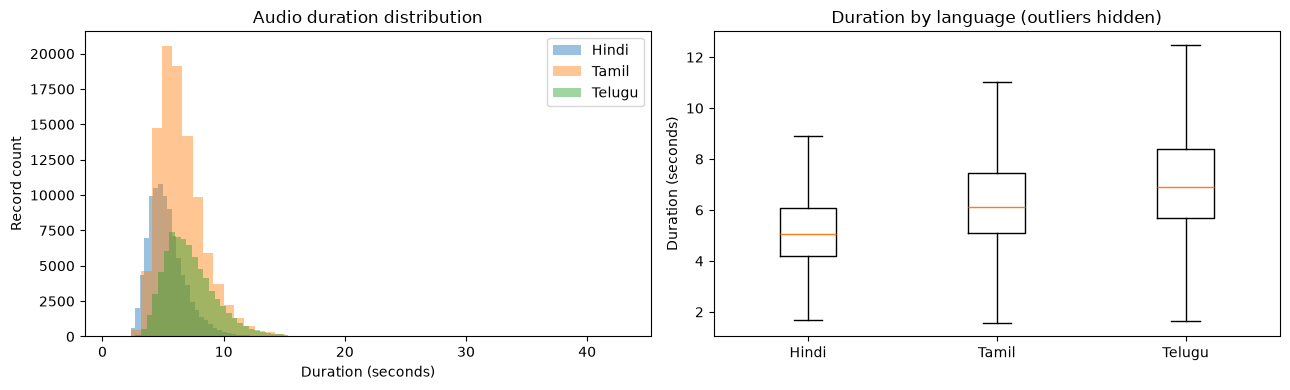

,language,split,duration_band,records
0,Hindi,train,2–15 sec,91728
1,Hindi,train,Above 15 sec,19
2,Hindi,train,Below 2 sec,5
3,Hindi,valid,2–15 sec,3150
4,Hindi,valid,Above 15 sec,1
5,Tamil,train,2–15 sec,95559
6,Tamil,train,Above 15 sec,175
7,Tamil,train,Below 2 sec,28
8,Tamil,valid,2–15 sec,2768
9,Tamil,valid,Above 15 sec,2


In [24]:
duration_summary = (
    metadata_df.groupby(["language", "split"])["duration"]
    .agg(records="count", mean="mean", median="median", std="std",
         minimum="min", maximum="max")
    .reset_index()
)
display(duration_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for language in LANGUAGES:
    values = metadata_df.loc[
        (metadata_df["language"] == language) & metadata_df["duration"].notna(),
        "duration"
    ]
    axes[0].hist(values, bins=50, alpha=0.45, label=language)
axes[0].set_title("Audio duration distribution")
axes[0].set_xlabel("Duration (seconds)")
axes[0].set_ylabel("Record count")
axes[0].legend()

duration_by_language = [
    metadata_df.loc[metadata_df["language"] == lang, "duration"].dropna().values
    for lang in LANGUAGES
]
axes[1].boxplot(
    duration_by_language,
    tick_labels=list(LANGUAGES.keys()),
    showfliers=False
)
axes[1].set_title("Duration by language (outliers hidden)")
axes[1].set_ylabel("Duration (seconds)")
plt.tight_layout()
plt.show()

duration_screen = (
    metadata_df.assign(
        duration_band=np.select(
            [
                metadata_df["duration"] < 2,
                metadata_df["duration"] <= 15
            ],
            ["Below 2 sec", "2–15 sec"],
            default="Above 15 sec"
        )
    )
    .groupby(["language", "split", "duration_band"])
    .size().rename("records").reset_index()
)
display(duration_screen)

## 6. Transcript metadata checks

,language,records,blank_transcripts,min_chars,median_chars,mean_chars,max_chars,language_code_mismatches
0,Hindi,94903,0,16,57.0,57.49,143,0
1,Tamil,98532,0,12,93.0,95.88,235,0
2,Telugu,73052,0,25,82.0,84.40,173,0


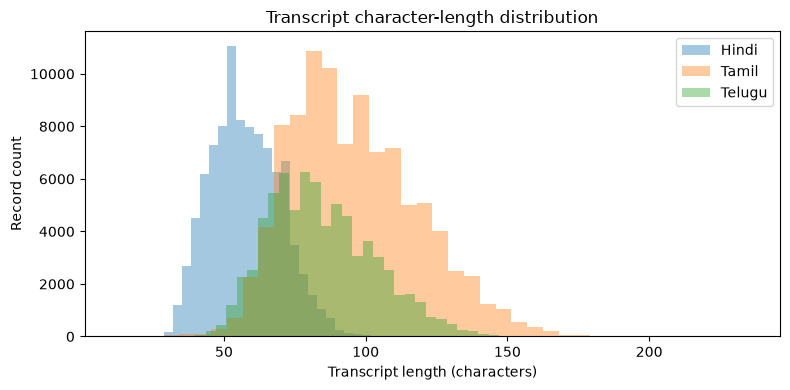

In [25]:
expected_codes = {"Hindi": "hi", "Tamil": "ta", "Telugu": "te"}

metadata_df["transcript_clean"] = metadata_df["text"].fillna("").astype(str).str.strip()
metadata_df["transcript_length_chars"] = metadata_df["transcript_clean"].str.len()
metadata_df["language_code_matches"] = metadata_df.apply(
    lambda row: str(row["lang"]).lower() == expected_codes[row["language"]],
    axis=1
)

transcript_summary = (
    metadata_df.groupby("language")
    .agg(
        records=("fname", "count"),
        blank_transcripts=("transcript_clean", lambda s: s.eq("").sum()),
        min_chars=("transcript_length_chars", "min"),
        median_chars=("transcript_length_chars", "median"),
        mean_chars=("transcript_length_chars", "mean"),
        max_chars=("transcript_length_chars", "max"),
        language_code_mismatches=("language_code_matches", lambda s: (~s).sum())
    )
    .reset_index()
)
display(transcript_summary.round(2))

plt.figure(figsize=(8, 4))
for language in LANGUAGES:
    values = metadata_df.loc[
        metadata_df["language"] == language, "transcript_length_chars"
    ]
    plt.hist(values, bins=40, alpha=0.4, label=language)
plt.title("Transcript character-length distribution")
plt.xlabel("Transcript length (characters)")
plt.ylabel("Record count")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Speaker distribution and split leakage check

,language,split,unique_speakers
0,Hindi,train,101
1,Hindi,valid,20
2,Tamil,train,138
3,Tamil,valid,20
4,Telugu,train,84
5,Telugu,valid,20


,Language,Train speakers,Validation speakers,Overlapping speakers,Speaker-disjoint split
0,Hindi,101,20,20,False
1,Tamil,138,20,20,False
2,Telugu,84,20,20,False


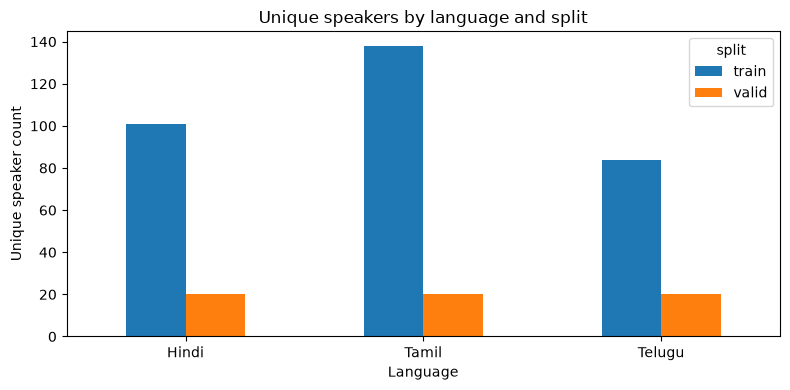

In [26]:
speaker_summary = (
    metadata_df.groupby(["language", "split"])["speaker_id"]
    .nunique().rename("unique_speakers").reset_index()
)
display(speaker_summary)

speaker_overlap_rows = []
for language in LANGUAGES:
    train_ids = set(metadata_df.loc[
        (metadata_df["language"] == language) & (metadata_df["split"] == "train"),
        "speaker_id"
    ].dropna())
    valid_ids = set(metadata_df.loc[
        (metadata_df["language"] == language) & (metadata_df["split"] == "valid"),
        "speaker_id"
    ].dropna())
    overlap = train_ids & valid_ids
    speaker_overlap_rows.append({
        "Language": language,
        "Train speakers": len(train_ids),
        "Validation speakers": len(valid_ids),
        "Overlapping speakers": len(overlap),
        "Speaker-disjoint split": len(overlap) == 0
    })

speaker_overlap_df = pd.DataFrame(speaker_overlap_rows)
display(speaker_overlap_df)

# Visualize speaker counts by split
speaker_pivot = speaker_summary.pivot(
    index="language", columns="split", values="unique_speakers"
).fillna(0)
ax = speaker_pivot.plot(kind="bar", figsize=(8, 4))
ax.set_title("Unique speakers by language and split")
ax.set_xlabel("Language")
ax.set_ylabel("Unique speaker count")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 8 Full-dataset audio quality audit

In [27]:
AUDIO_CSV = Path("kathbath_audio_quality_full.csv")
CHECKPOINT_EVERY = 500

# Load existing results so a rerun can skip completed files.
if AUDIO_CSV.exists():
    audio_results_df = pd.read_csv(AUDIO_CSV)
    completed_keys = set(
        zip(audio_results_df["language"], audio_results_df["split"], audio_results_df["filename"])
    )
    print(f"Resuming: {len(completed_keys):,} records already saved.")
else:
    audio_results_df = pd.DataFrame()
    completed_keys = set()

audio_rows = []
started_at = time.time()

for language, dataset in datasets_by_language.items():
    for split_name, split_data in dataset.items():
        audio_data = split_data.cast_column("audio_filepath", Audio(decode=False))

        for idx, row in enumerate(audio_data):
            key = (language, split_name, str(row["fname"]))
            if key in completed_keys:
                continue

            result = {
                "language": language,
                "split": split_name,
                "filename": str(row["fname"]),
                "metadata_duration_sec": row.get("duration"),
                "sample_rate": np.nan,
                "channels": np.nan,
                "format": None,
                "actual_duration_sec": np.nan,
                "rms": np.nan,
                "rms_dbfs": np.nan,
                "peak_amplitude": np.nan,
                "clipping_percentage": np.nan,
                "status": "ERROR",
                "error": None
            }

            try:
                audio_info = row["audio_filepath"]
                audio_bytes = audio_info.get("bytes")

                if audio_bytes is not None:
                    audio_source = io.BytesIO(audio_bytes)
                elif audio_info.get("path"):
                    audio_source = audio_info["path"]
                else:
                    raise ValueError("Audio row has neither bytes nor path")

                with sf.SoundFile(audio_source) as audio_file:
                    sample_rate = audio_file.samplerate
                    channels = audio_file.channels
                    audio_format = audio_file.format
                    frames = len(audio_file)
                    signal = audio_file.read(dtype="float32", always_2d=True)

                if signal.size == 0:
                    raise ValueError("Empty audio signal")

                mono = signal.mean(axis=1)
                rms = float(np.sqrt(np.mean(mono ** 2)))
                peak = float(np.max(np.abs(mono)))
                clipping_pct = float(np.mean(np.abs(mono) >= 0.999) * 100)

                result.update({
                    "sample_rate": sample_rate,
                    "channels": channels,
                    "format": audio_format,
                    "actual_duration_sec": frames / sample_rate,
                    "rms": rms,
                    "rms_dbfs": 20 * np.log10(rms) if rms > 0 else -np.inf,
                    "peak_amplitude": peak,
                    "clipping_percentage": clipping_pct,
                    "status": "OK"
                })

            except Exception as exc:
                result["error"] = str(exc)

            audio_rows.append(result)
            completed_keys.add(key)

            if len(audio_rows) >= CHECKPOINT_EVERY:
                new_df = pd.DataFrame(audio_rows)
                if AUDIO_CSV.exists():
                    new_df.to_csv(AUDIO_CSV, mode="a", header=False, index=False)
                else:
                    new_df.to_csv(AUDIO_CSV, index=False)
                audio_rows = []
                print(f"Checkpoint saved. Total completed: {len(completed_keys):,}")

# Save remaining rows
if audio_rows:
    new_df = pd.DataFrame(audio_rows)
    if AUDIO_CSV.exists():
        new_df.to_csv(AUDIO_CSV, mode="a", header=False, index=False)
    else:
        new_df.to_csv(AUDIO_CSV, index=False)

print(f"Audio audit finished in {(time.time() - started_at) / 60:.1f} minutes.")
print(f"Results: {AUDIO_CSV.resolve()}")

Resuming: 266,487 records already saved.
Audio audit finished in 3.8 minutes.
Results: C:\Users\palam\OneDrive\Desktop\ds-ai-lab\Group-3-DS-and-AI-Lab-Project\milestones\Milestone-2\kathbath\kathbath_audio_quality_full.csv


## 9. Summarize full audio audit

In [28]:
audio_quality_df = pd.read_csv(AUDIO_CSV)

audio_summary = (
    audio_quality_df.groupby(["language", "split"])
    .agg(
        records=("filename", "count"),
        decode_errors=("status", lambda s: (~s.eq("OK")).sum()),
        mean_sample_rate=("sample_rate", "mean"),
        channel_values=("channels", lambda s: ", ".join(map(str, sorted(s.dropna().unique())))),
        mean_duration_sec=("actual_duration_sec", "mean"),
        mean_rms=("rms", "mean"),
        median_rms=("rms", "median"),
        max_peak=("peak_amplitude", "max"),
        files_with_clipping=("clipping_percentage", lambda s: (s > 0).sum())
    )
    .reset_index()
)
display(audio_summary.round(4))

,language,split,records,decode_errors,mean_sample_rate,channel_values,mean_duration_sec,mean_rms,median_rms,max_peak,files_with_clipping
0,Hindi,train,91752,0,16000.0,1,5.2870,0.0771,0.0682,1.0,4483
1,Hindi,valid,3151,0,16000.0,1,5.5313,0.0767,0.0631,1.0,201
2,Tamil,train,95762,0,16000.0,1,6.4623,0.0934,0.0875,1.0,3995
3,Tamil,valid,2770,0,16000.0,1,6.5249,0.1063,0.1089,1.0,181
4,Telugu,train,70673,0,16000.0,1,7.2199,0.0663,0.0560,1.0,2985
5,Telugu,valid,2379,0,16000.0,1,7.5782,0.0707,0.0597,1.0,210


## 10. Audio-quality visualizations

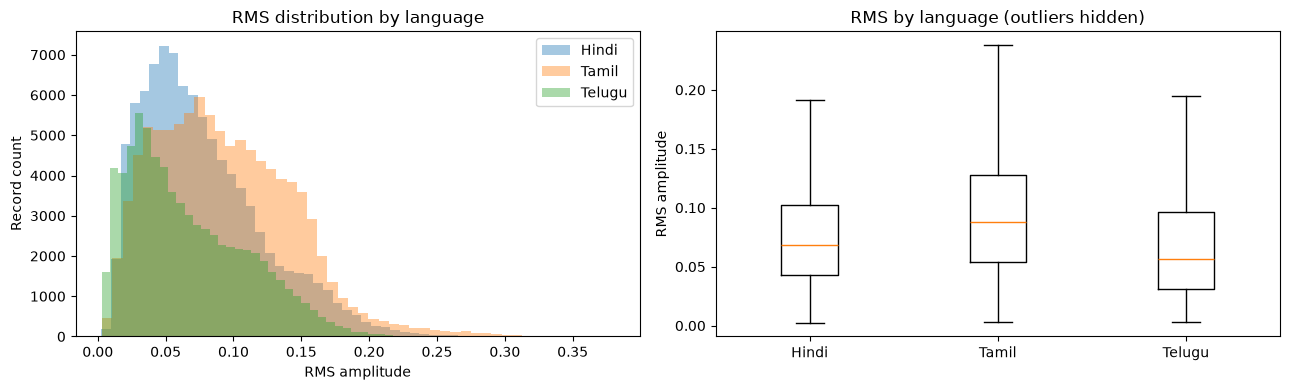

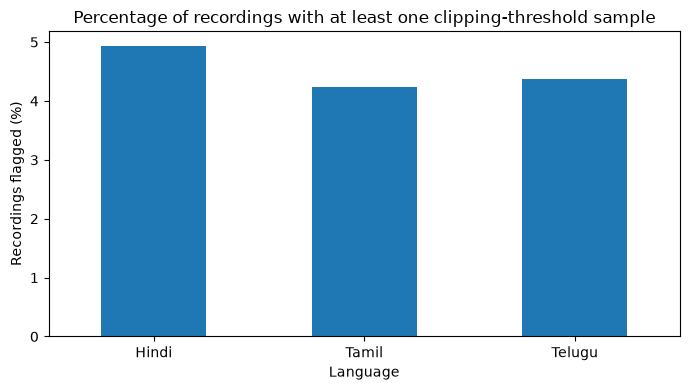

In [29]:
successful_audio = audio_quality_df[audio_quality_df["status"].eq("OK")].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for language in LANGUAGES:
    values = successful_audio.loc[
        successful_audio["language"] == language, "rms"
    ].dropna()
    axes[0].hist(values, bins=50, alpha=0.4, label=language)
axes[0].set_title("RMS distribution by language")
axes[0].set_xlabel("RMS amplitude")
axes[0].set_ylabel("Record count")
axes[0].legend()

rms_by_language = [
    successful_audio.loc[successful_audio["language"] == lang, "rms"].dropna().values
    for lang in LANGUAGES
]

axes[1].boxplot(
    rms_by_language,
    tick_labels=list(LANGUAGES.keys()),
    showfliers=False
)
axes[1].set_title("RMS by language (outliers hidden)")
axes[1].set_ylabel("RMS amplitude")
plt.tight_layout()
plt.show()

clip_rate = (
    successful_audio.assign(has_clipping=successful_audio["clipping_percentage"] > 0)
    .groupby("language")["has_clipping"].mean().mul(100)
)
ax = clip_rate.reindex(list(LANGUAGES.keys())).plot(kind="bar", figsize=(7, 4))
ax.set_title("Percentage of recordings with at least one clipping-threshold sample")
ax.set_xlabel("Language")
ax.set_ylabel("Recordings flagged (%)") 
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

# 11. Librosa acoustic-feature EDA (sample)

In [30]:
LIBROSA_SAMPLES_PER_LANGUAGE = 2000
librosa_rows = []
librosa_examples = {}

for language, dataset in datasets_by_language.items():
    train_data = dataset['train'].shuffle(seed=SEED).select(
        range(min(LIBROSA_SAMPLES_PER_LANGUAGE, len(dataset['train'])))
    ).cast_column('audio_filepath', Audio(decode=False))

    for row in train_data:
        audio_info = row['audio_filepath']
        audio_bytes = audio_info.get('bytes')
        if audio_bytes is not None:
            audio_source = io.BytesIO(audio_bytes)
        elif audio_info.get('path'):
            audio_source = audio_info['path']
        else:
            librosa_rows.append({'language': language, 'filename': str(row['fname']), 'status': 'ERROR: no audio bytes/path'})
            continue

        try:
            with sf.SoundFile(audio_source) as f:
                sr = f.samplerate
                y = f.read(dtype='float32', always_2d=True).mean(axis=1)
            if y.size == 0:
                raise ValueError('Empty audio signal')

            # Features are computed at the original sample rate; no resampling is applied.
            mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
            centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
            zcr = librosa.feature.zero_crossing_rate(y=y)
            rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr, roll_percent=0.85)

            librosa_rows.append({
                'language': language, 'filename': str(row['fname']), 'sample_rate': sr,
                'duration_sec': len(y) / sr,
                'mfcc_1_mean': float(np.mean(mfcc[0])),
                'mfcc_2_mean': float(np.mean(mfcc[1])),
                'spectral_centroid_mean_hz': float(np.mean(centroid)),
                'zero_crossing_rate_mean': float(np.mean(zcr)),
                'spectral_rolloff_mean_hz': float(np.mean(rolloff)),
                'status': 'OK'
            })
            if language not in librosa_examples:
                librosa_examples[language] = (y, sr, str(row['fname']))
        except Exception as exc:
            librosa_rows.append({'language': language, 'filename': str(row['fname']), 'status': f'ERROR: {exc}'})

librosa_eda_df = pd.DataFrame(librosa_rows)
LIBROSA_CSV = Path('kathbath_librosa_acoustic_sample.csv')
librosa_eda_df.to_csv(LIBROSA_CSV, index=False)
print(f'Saved: {LIBROSA_CSV.resolve()}')
print(f'Recordings sampled: {len(librosa_eda_df):,}')
display(librosa_eda_df.groupby(['language', 'status']).size().rename('records').reset_index())
display(librosa_eda_df[librosa_eda_df['status'].eq('OK')].groupby('language').agg(
    records=('filename', 'count'),
    mean_centroid_hz=('spectral_centroid_mean_hz', 'mean'),
    mean_zcr=('zero_crossing_rate_mean', 'mean'),
    mean_rolloff_hz=('spectral_rolloff_mean_hz', 'mean')
).round(3))

Saved: C:\Users\palam\OneDrive\Desktop\ds-ai-lab\Group-3-DS-and-AI-Lab-Project\milestones\Milestone-2\kathbath\kathbath_librosa_acoustic_sample.csv
Recordings sampled: 6,000


,language,status,records
0,Hindi,OK,2000
1,Tamil,OK,2000
2,Telugu,OK,2000


,records,mean_centroid_hz,mean_zcr,mean_rolloff_hz
language,,,,
Hindi,2000,1511.150,0.098,2934.616
Tamil,2000,1395.571,0.088,2675.733
Telugu,2000,1406.774,0.090,2743.842


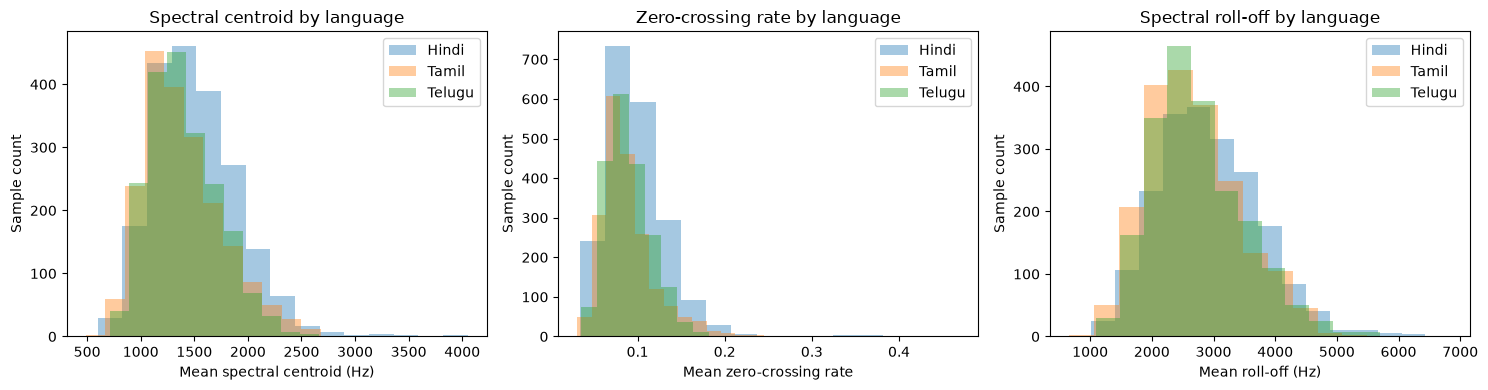

In [31]:
feature_df = librosa_eda_df[librosa_eda_df['status'].eq('OK')].copy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for language in LANGUAGES:
    values = feature_df.loc[feature_df['language'] == language, 'spectral_centroid_mean_hz'].dropna()
    axes[0].hist(values, bins=15, alpha=0.4, label=language)
axes[0].set_title('Spectral centroid by language')
axes[0].set_xlabel('Mean spectral centroid (Hz)')
axes[0].set_ylabel('Sample count')
axes[0].legend()

for language in LANGUAGES:
    values = feature_df.loc[feature_df['language'] == language, 'zero_crossing_rate_mean'].dropna()
    axes[1].hist(values, bins=15, alpha=0.4, label=language)
axes[1].set_title('Zero-crossing rate by language')
axes[1].set_xlabel('Mean zero-crossing rate')
axes[1].set_ylabel('Sample count')
axes[1].legend()

for language in LANGUAGES:
    values = feature_df.loc[feature_df['language'] == language, 'spectral_rolloff_mean_hz'].dropna()
    axes[2].hist(values, bins=15, alpha=0.4, label=language)
axes[2].set_title('Spectral roll-off by language')
axes[2].set_xlabel('Mean roll-off (Hz)')
axes[2].set_ylabel('Sample count')
axes[2].legend()
plt.tight_layout()
plt.show()

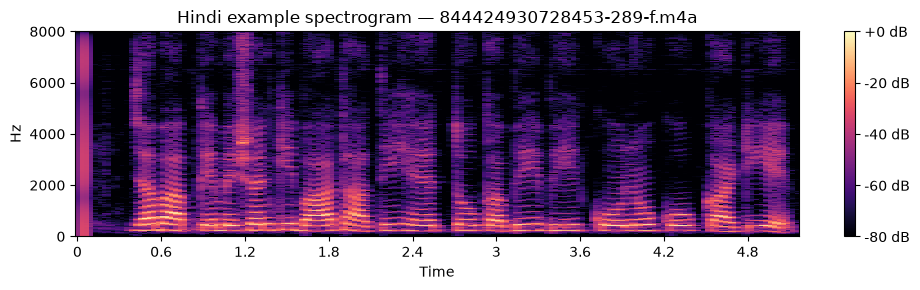

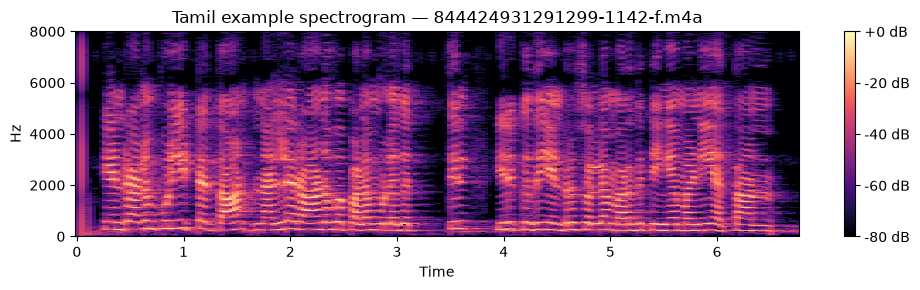

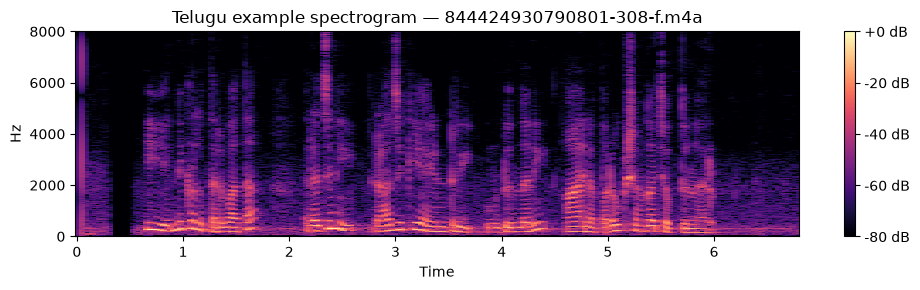

In [32]:
for language, (y, sr, filename) in librosa_examples.items():
    D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    plt.figure(figsize=(10, 3))
    librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='hz')
    plt.colorbar(format='%+2.0f dB')
    plt.title(f'{language} example spectrogram — {filename}')
    plt.tight_layout()
    plt.show()